# 3 N-BEATS: putting the decomposition *inside* the architecture

`09_composition_extra` computed a trend slope and a set of FFT band energies by hand, bolted them onto
the model as a second input stream, and measured the result: **the model ignored them.** The
diagnosis was that a linear layer over the raw window can already compute a trend slope — it is a
weighted sum — so we handed it a column it already had.

That diagnosis suggests an obvious next move. If trend and seasonality are the right vocabulary
for a timeseries, do not compute them outside the model and pass them in. **Make them the shape
the model is allowed to predict in.**

That is N-BEATS (Oreshkin et al., 2020). Instead of a network that outputs 24 free numbers, you
get a network that outputs *coefficients of a basis* — a polynomial for trend, a Fourier series
for seasonality — and the forecast is whatever those coefficients build. The architecture cannot
predict an arbitrary squiggle. It can only predict a trend plus a seasonal pattern, and it has to
say how much of each.

**You cannot download this one.** There is no pretrained N-BEATS the way there is a pretrained
`resnet18`, and the reason is structural rather than an oversight: N-BEATS is fitted per series
and per horizon, so there is no transferable feature extractor to ship. (`neuralforecast` has an
implementation, but it depends on pytorch-lightning *and* pyspark, and its top-level model wants
a Lightning batch dict.) So we build it — about forty lines, mirroring
[`neuralforecast/models/nbeats.py`](https://github.com/Nixtla/neuralforecast/blob/main/neuralforecast/models/nbeats.py),
close enough that you can read theirs afterwards and recognise every part.

In [1]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from notebooktester import param

from ett import load_ett, window_index

W, H = 168, 24        # a week of history, a day of horizon
PERIOD = 24           # the seasonality we believe is in this data
EPOCHS, SEEDS = param(12, test=1), (0, 1, 2)
torch.manual_seed(0)

## 3.1 A series with something for a Fourier basis to find

A seasonal basis is only worth having if there is seasonality. `02_basemodels` measured ETTh1's
oil temperature and found the opposite: `acf(1h)` near 1, `acf(24h)` weak, most spectral energy at
long periods. A thermal quantity integrates its input, so it drifts rather than cycles.

So this notebook runs on **Melbourne pedestrian counts** — hourly footfall from street sensors,
where the hour of the day is most of the story. We come back to ETTh1 at the end, on purpose.

In [2]:
def load_pedestrian(n_series: int = 8) -> list[torch.Tensor]:
    ds = load_dataset(
        "Monash-University/monash_tsf", revision="refs/convert/parquet",
        data_files={"test": "pedestrian_counts/test/0000.parquet"},
    )["test"]
    out = []
    for row in ds:
        s = np.asarray(row["target"], dtype="float32")
        s = s[~np.isnan(s)]
        if len(s) >= 6 * (W + H):
            out.append(torch.tensor(s))
        if len(out) >= n_series:
            break
    return out


def split_scale_window(series: list[torch.Tensor], stride: int = 6) -> dict:
    # 60/20/20 in time, per series, scaled on that series' own training span - 01_windowing
    parts = {"train": [[], []], "val": [[], []], "test": [[], []]}
    for s in series:
        n = len(s)
        cuts = {"train": (0, int(0.6 * n)), "val": (int(0.6 * n), int(0.8 * n)),
                "test": (int(0.8 * n), n)}
        mu = s[: cuts["train"][1]].mean()
        sigma = s[: cuts["train"][1]].std().clamp(min=1e-6)
        for split, (a, b) in cuts.items():
            v = (s[a:b] - mu) / sigma
            win = v[window_index(len(v), W + H, stride)]
            parts[split][0].append(win[:, :W])
            parts[split][1].append(win[:, W:])
    return {k: (torch.cat(v[0]), torch.cat(v[1])) for k, v in parts.items()}


pedestrian = split_scale_window(load_pedestrian())
for split, (x, y) in pedestrian.items():
    print(f"{split:5s} x {tuple(x.shape)}  y {tuple(y.shape)}")

train x (72165, 168)  y (72165, 24)
val   x (23888, 168)  y (23888, 24)
test  x (23888, 168)  y (23888, 24)


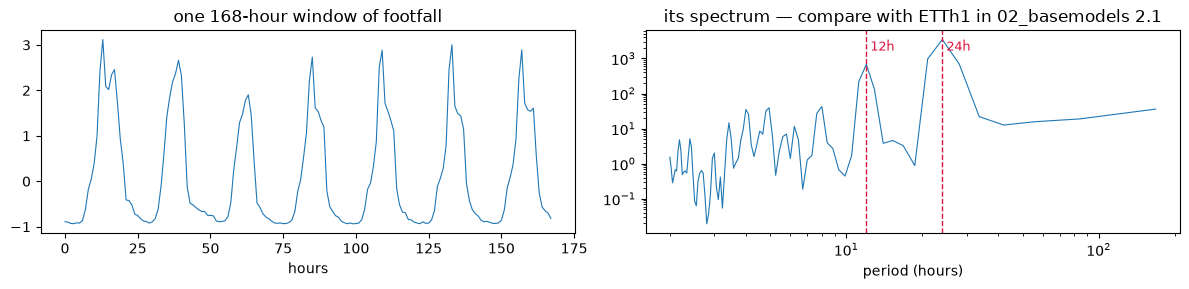

In [3]:
train_x = pedestrian["train"][0]
sample = train_x[0]

n = len(sample)
z = (sample - sample.mean()) * torch.hann_window(n, periodic=False)
power = torch.fft.rfft(z).abs() ** 2
periods = 1.0 / torch.fft.rfftfreq(n, d=1.0)[1:]

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(sample, lw=0.8)
ax[0].set_title("one 168-hour window of footfall")
ax[0].set_xlabel("hours")
ax[1].loglog(periods, power[1:], lw=0.8)
for hours, label in ((12, "12h"), (24, "24h")):
    ax[1].axvline(hours, color="crimson", ls="--", lw=1)
    ax[1].text(hours, power[1:].max(), f" {label}", color="crimson", va="top", fontsize=9)
ax[1].set_xlabel("period (hours)")
ax[1].set_title("its spectrum — compare with ETTh1 in 02_basemodels 2.1")
plt.tight_layout()

A spike at 24 hours you can see without squinting. That is the thing a Fourier basis is for.

## 3.2 A basis is a fixed set of shapes; the network picks the mix

Every N-BEATS block does the same two steps:

1. an ordinary MLP maps the input window to a short vector of coefficients, **theta**;
2. a **basis** turns theta into two curves — a *backcast* (its reconstruction of the input) and a
   *forecast* (its prediction of the future).

The basis has **no learnable parameters**. It is a fixed matrix of shapes, and all the network
does is decide how much of each shape to use. Swap the basis and you change what the block is
*able* to say.

The trend basis is powers of normalised time: a constant, a ramp, a curve, a bend.

theta for this basis has 8 numbers (4 for the backcast, 4 for the forecast)


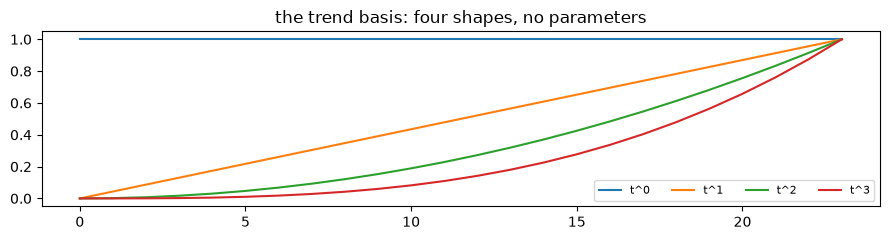

In [4]:
class TrendBasis(nn.Module):
    # theta -> a low-order polynomial in normalised time, for backcast and forecast

    backcast_basis: torch.Tensor
    forecast_basis: torch.Tensor

    def __init__(self, degree: int, backcast_size: int, forecast_size: int):
        super().__init__()
        self.size = degree + 1
        powers = lambda n: torch.stack([torch.linspace(0, 1, n) ** p for p in range(self.size)])
        self.register_buffer("backcast_basis", powers(backcast_size))   # (size, W)
        self.register_buffer("forecast_basis", powers(forecast_size))   # (size, H)

    def forward(self, theta):
        backcast = torch.einsum("bp,pt->bt", theta[:, : self.size], self.backcast_basis)
        forecast = torch.einsum("bp,pt->bt", theta[:, self.size :], self.forecast_basis)
        return backcast, forecast


trend = TrendBasis(degree=3, backcast_size=W, forecast_size=H)
fig, ax = plt.subplots(figsize=(9, 2.5))
for p, row in enumerate(trend.forecast_basis):
    ax.plot(row, label=f"t^{p}")
ax.set_title("the trend basis: four shapes, no parameters")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
print(f"theta for this basis has {2 * trend.size} numbers "
      f"({trend.size} for the backcast, {trend.size} for the forecast)")

And the seasonal basis is a Fourier series: sines and cosines at harmonics of a period you name.

Look at what that means. In `09_composition_extra` we computed FFT *band energies* and handed them to
the model as inputs. Here the same sines and cosines are the **output** vocabulary — the model
does not receive a spectrum, it predicts *in* one. Same mathematics, opposite direction.

reconstructs a pure 24h cosine exactly: max error 4.47e-07


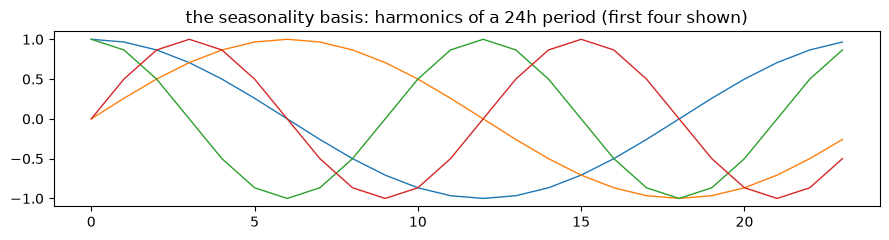

In [5]:
class SeasonalityBasis(nn.Module):
    # theta -> a Fourier series at harmonics of a known period

    backcast_basis: torch.Tensor
    forecast_basis: torch.Tensor

    def __init__(self, harmonics: int, period: int, backcast_size: int, forecast_size: int):
        super().__init__()
        self.size = 2 * harmonics
        # the backcast grid runs up to the forecast origin, the forecast grid starts at it,
        # so the two are one continuous timeline and the phase carries across the boundary
        for name, n, offset in (("backcast", backcast_size, -backcast_size),
                                ("forecast", forecast_size, 0)):
            t = (torch.arange(n, dtype=torch.float32) + offset) / period
            rows = [f(2 * np.pi * k * t)
                    for k in range(1, harmonics + 1) for f in (torch.cos, torch.sin)]
            self.register_buffer(f"{name}_basis", torch.stack(rows))

    def forward(self, theta):
        backcast = torch.einsum("bp,pt->bt", theta[:, : self.size], self.backcast_basis)
        forecast = torch.einsum("bp,pt->bt", theta[:, self.size :], self.forecast_basis)
        return backcast, forecast


seasonal = SeasonalityBasis(harmonics=6, period=PERIOD, backcast_size=W, forecast_size=H)

fig, ax = plt.subplots(figsize=(9, 2.5))
for i in range(4):
    ax.plot(seasonal.forecast_basis[i], lw=1)
ax.set_title(f"the seasonality basis: harmonics of a {PERIOD}h period (first four shown)")
plt.tight_layout()

# a basis is only trustworthy if it can express the thing it claims to
target = torch.cos(2 * np.pi * torch.arange(H, dtype=torch.float32) / PERIOD)
theta = torch.zeros(1, 2 * seasonal.size)
theta[0, seasonal.size] = 1.0          # one unit of the first cosine, nothing else
_, reconstructed = seasonal(theta)
print(f"reconstructs a pure {PERIOD}h cosine exactly: "
      f"max error {float((reconstructed[0] - target).abs().max()):.2e}")

## 3.3 The block, and the stacking that makes it work

A block is the MLP plus a basis. The interesting part is what happens *between* blocks.

Each block emits a backcast — its own account of the input — and that account is **subtracted from
the input before the next block sees it**. Block two therefore works on what block one could not
explain. Meanwhile the forecasts are **added up**. Oreshkin et al. call this *doubly residual
stacking*, and it is the whole mechanism: subtract backwards, accumulate forwards.

Give the first block a trend basis and the second a seasonal one, and the model is forced to
explain the trend first and treat what is left as seasonal. The decomposition is not something you
compute; it is something the architecture cannot avoid doing.

In [6]:
class IdentityBasis(nn.Module):
    # theta IS the curve - no structure imposed. This is "generic" N-BEATS.

    def __init__(self, backcast_size: int, forecast_size: int):
        super().__init__()
        self.size = backcast_size

    def forward(self, theta):
        return theta[:, : self.size], theta[:, self.size :]


class NBeatsBlock(nn.Module):
    def __init__(self, basis, input_size: int, theta_size: int, hidden: int = 256, layers: int = 3):
        super().__init__()
        mlp, d = [], input_size
        for _ in range(layers):
            mlp += [nn.Linear(d, hidden), nn.ReLU()]
            d = hidden
        self.mlp = nn.Sequential(*mlp)
        self.theta = nn.Linear(hidden, theta_size)
        self.basis = basis

    def forward(self, x):
        return self.basis(self.theta(self.mlp(x)))


class NBeats(nn.Module):
    def __init__(self, blocks: list[NBeatsBlock]):
        super().__init__()
        self.blocks = nn.ModuleList(blocks)

    def forward(self, x, per_block: bool = False):
        residual = x
        forecast = x[:, -1:].expand(-1, H).clone()    # start at the naive forecast
        contributions = []
        for block in self.blocks:
            backcast, block_forecast = block(residual)
            residual = residual - backcast            # <- subtract what was explained
            forecast = forecast + block_forecast      # <- accumulate what was predicted
            contributions.append(block_forecast)
        return (forecast, contributions) if per_block else forecast


def interpretable(degree=3, harmonics=6, period=PERIOD, hidden=256):
    t = TrendBasis(degree, W, H)
    s = SeasonalityBasis(harmonics, period, W, H)
    return NBeats([NBeatsBlock(t, W, 2 * t.size, hidden),
                   NBeatsBlock(s, W, 2 * s.size, hidden)])


def generic(n_blocks=2, hidden=256):
    return NBeats([NBeatsBlock(IdentityBasis(W, H), W, W + H, hidden) for _ in range(n_blocks)])


model = interpretable()
out, parts = model(train_x[:4], per_block=True)
print(f"forecast {tuple(out.shape)}, from {len(parts)} stacks of {tuple(parts[0].shape)}")
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

forecast (4, 24), from 2 stacks of (4, 24)
357,920 parameters


## 3.4 Baselines first

Same discipline as every other notebook in this lesson: the free baselines, then the cheap trained
one, then the expensive one. `02_basemodels` predicted that on a strongly seasonal series the
*seasonal* naive would be the strong baseline and plain naive the weak one — the reverse of ETTh1.
Check that before going further.

In [7]:
def mae(y, yhat):
    return float((y - yhat).abs().mean())


def fit(make_model, data, seeds=SEEDS, epochs=EPOCHS, lr=1e-3, batch_size=128):
    xtr, ytr = data["train"]
    xva, yva = data["val"]
    xte, yte = data["test"]
    val, test, secs = [], [], []
    for seed in seeds:
        torch.manual_seed(seed)
        model = make_model()
        opt = torch.optim.Adam(model.parameters(), lr=lr)
        loss_fn = nn.MSELoss()
        loader = DataLoader(TensorDataset(xtr, ytr), batch_size=batch_size, shuffle=True)
        t0 = time.time()
        for _ in range(epochs):
            for xb, yb in loader:
                opt.zero_grad()
                loss_fn(model(xb), yb).backward()
                opt.step()
        secs.append(time.time() - t0)
        model.eval()
        with torch.no_grad():
            val.append(mae(yva, model(xva)))
            test.append(mae(yte, model(xte)))
    return {"mae": float(np.mean(val)), "std": float(np.std(val)),
            "test": float(np.mean(test)), "secs": float(np.mean(secs)),
            "params": sum(p.numel() for p in model.parameters()), "model": model}


class Linear(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(W, H)

    def forward(self, x):
        return self.fc(x)


xva, yva = pedestrian["val"]
results: dict[str, dict[str, Any]] = {
    "naive (repeat last)": {"mae": mae(yva, xva[:, -1:].expand(-1, H)), "std": 0.0,
                            "test": float("nan"), "secs": 0.0, "params": 0},
    "seasonal naive (24h)": {"mae": mae(yva, xva[:, -PERIOD:][:, :H]), "std": 0.0,
                             "test": float("nan"), "secs": 0.0, "params": 0},
}
for name, r in results.items():
    print(f"{name:24s} val MAE {r['mae']:.4f}")

naive (repeat last)      val MAE 1.1530
seasonal naive (24h)     val MAE 0.3055


In [8]:
for name, make in (("linear", Linear), ("N-BEATS generic", generic),
                   ("N-BEATS interpretable", interpretable)):
    r = fit(make, pedestrian)
    results[name] = r
    print(f"{name:24s} val MAE {r['mae']:.4f} +/- {r['std']:.4f}   test {r['test']:.4f}   "
          f"{r['params']:>8,} params   {r['secs']:5.1f}s")

linear                   val MAE 0.2626 +/- 0.0018   test 0.2614      4,056 params     1.8s


N-BEATS generic          val MAE 0.2808 +/- 0.0048   test 0.3019    448,384 params    18.5s


N-BEATS interpretable    val MAE 0.2918 +/- 0.0028   test 0.3078    357,920 params    16.3s


In [9]:
print(f"{'model':24s} {'val MAE':>9} {'+/-':>7} {'test':>8} {'params':>9} {'secs':>7}")
print("-" * 68)
for name in sorted(results, key=lambda k: results[k]["mae"]):
    r = results[name]
    test = f"{r['test']:.4f}" if r["test"] == r["test"] else "-"
    print(f"{name:24s} {r['mae']:9.4f} {r['std']:7.4f} {test:>8} {r['params']:9,} {r['secs']:7.1f}")

model                      val MAE     +/-     test    params    secs
--------------------------------------------------------------------
linear                      0.2626  0.0018   0.2614     4,056     1.8
N-BEATS generic             0.2808  0.0048   0.3019   448,384    18.5
N-BEATS interpretable       0.2918  0.0028   0.3078   357,920    16.3
seasonal naive (24h)        0.3055  0.0000        -         0     0.0
naive (repeat last)         1.1530  0.0000        -         0     0.0


**The linear layer wins again.** Four thousand parameters, under two seconds, and neither N-BEATS
variant reaches it — on the series we chose *because* it has the structure N-BEATS is built for.

Before accepting that, the obvious objection: is N-BEATS simply under-trained? Nine configurations
were run separately to find out (each takes one to three minutes, which is why they are not in
this notebook — E1 asks you to reproduce them):

| configuration | val MAE |
|---|---|
| linear | **0.2611** |
| generic, hidden 512, 40 epochs | 0.2758 |
| generic, hidden 256, 40 epochs, lr 3e-4 | 0.2762 |
| generic, hidden 256, 40 epochs | 0.2788 |
| generic, hidden 64, 40 epochs | 0.2883 |
| interpretable, 40 epochs, lr 3e-4 | 0.2886 |
| interpretable, 3 stacks (+ weekly period) | 0.2894 |
| interpretable, 12 harmonics | 0.2944 |

Wider, narrower, longer, slower, more harmonics, an extra weekly stack — every one of them loses.
The result is not a training artefact.

**Why the cheap model wins here is worth working out.** `nn.Linear(168, 24)` learns one weight per
input hour per output hour. "The footfall at 3pm tomorrow resembles the footfall at 3pm today and
3pm last week" is expressible as *a large weight on lag 24 and lag 168* — the linear layer can say
it directly, in one parameter each. N-BEATS has to reach the same conclusion through a
three-layer MLP and a basis projection. With **72,165 training windows** there is more than enough
data to learn the direct route, and the extra machinery only adds ways to be wrong.

Hold that thought until 3.6, where the data runs out.

## 3.5 The payoff: ask the model what it thinks the series is made of

Whatever the scores say, the interpretable model can do something none of the others in this
lesson can. `per_block=True` returns each stack's contribution separately, so you can plot the
trend it found and the seasonality it found as **two curves that sum to the forecast**.

This is not a visualisation trick bolted on afterwards. The stacks are separate because the
architecture made them separate.

mean |trend contribution|       0.9370
mean |seasonality contribution| 1.0038
ratio seasonality / trend       1.071


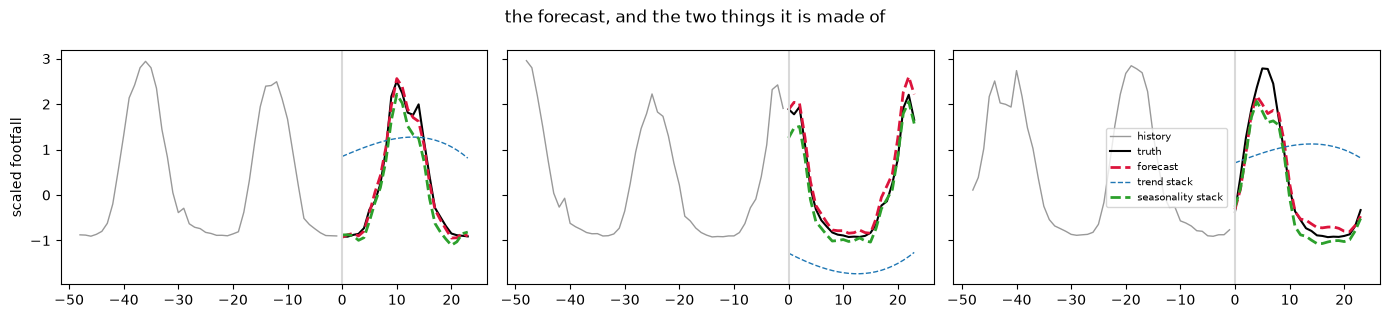

In [10]:
interp = results["N-BEATS interpretable"]["model"]
interp.eval()
with torch.no_grad():
    forecast, (trend_part, seasonal_part) = interp(xva[:512], per_block=True)

picks = [3, 61, 140]
fig, axes = plt.subplots(1, len(picks), figsize=(14, 3.2), sharey=True)
for ax, i in zip(axes, picks):
    ax.plot(range(-48, 0), xva[i, -48:], color="0.6", lw=1, label="history")
    ax.plot(range(H), yva[i], color="k", lw=1.5, label="truth")
    ax.plot(range(H), forecast[i], color="crimson", lw=2, ls="--", label="forecast")
    ax.plot(range(H), trend_part[i], color="tab:blue", lw=1, ls="--", label="trend stack")
    ax.plot(range(H), seasonal_part[i], color="tab:green", lw=2, ls="--", label="seasonality stack")
    ax.axvline(0, color="0.85")
axes[0].set_ylabel("scaled footfall")
axes[-1].legend(fontsize=7)
fig.suptitle("the forecast, and the two things it is made of")
plt.tight_layout()

ratio = float(seasonal_part.abs().mean() / trend_part.abs().mean())
print(f"mean |trend contribution|       {float(trend_part.abs().mean()):.4f}")
print(f"mean |seasonality contribution| {float(seasonal_part.abs().mean()):.4f}")
print(f"ratio seasonality / trend       {ratio:.3f}")

The two stacks carry **comparable weight** — the seasonal component is doing at least as much work
as the trend, which is what you would expect from a spectrum with a 24-hour spike in it. The model
has been forced to state, in numbers you can read, how much of its forecast is "the level is
drifting" and how much is "it is 3pm".

Note what this is worth *given* that the model lost on score. You now have a model you can
interrogate and a model that is more accurate, and they are not the same model. That is an
ordinary situation, and which one you ship depends on whether anybody has to defend the forecast
to a human. Accuracy is one axis; being able to answer *why* is another.

Keep this ratio. It is about to change.

## 3.6 The same architecture on a series that has no daily cycle

`02_basemodels` and `04_probabilistic` ran on ETTh1's oil temperature, where the spectrum is
dominated by long periods and `acf(24h)` is weak. The architecture has a seasonality stack tuned to
a 24-hour period. There is nothing there for it to find.

Run it unchanged and watch the ratio.

In [11]:
ett = load_ett()
mu, sigma = ett.values[ett.splits["train"]].mean(), ett.values[ett.splits["train"]].std()
etth1 = {}
for split in ("train", "val", "test"):
    values = (ett.values[ett.splits[split]] - mu) / sigma
    win = values[window_index(len(values), W + H, 6)]
    etth1[split] = (win[:, :W], win[:, W:])
print({k: len(v[0]) for k, v in etth1.items()})

ett_xva, ett_yva = etth1["val"]
ett_results = {
    "naive (repeat last)": mae(ett_yva, ett_xva[:, -1:].expand(-1, H)),
    "seasonal naive (24h)": mae(ett_yva, ett_xva[:, -PERIOD:][:, :H]),
}
for name, make in (("linear", Linear), ("N-BEATS generic", generic),
                   ("N-BEATS interpretable", interpretable)):
    r = fit(make, etth1)
    ett_results[name] = r["mae"]
    if name == "N-BEATS interpretable":
        r["model"].eval()
        with torch.no_grad():
            _, (t_part, s_part) = r["model"](ett_xva[:512], per_block=True)
        ett_ratio = float(s_part.abs().mean() / t_part.abs().mean())

for name, score in sorted(ett_results.items(), key=lambda kv: kv[1]):
    print(f"{name:24s} val MAE {score:.4f}")
print(f"\nratio seasonality / trend on ETTh1:      {ett_ratio:.3f}")
print(f"                    on pedestrian:      {ratio:.3f}")

{'train': 1409, 'val': 449, 'test': 449}


N-BEATS generic          val MAE 0.1735
N-BEATS interpretable    val MAE 0.1763
naive (repeat last)      val MAE 0.1988
linear                   val MAE 0.2105
seasonal naive (24h)     val MAE 0.2162

ratio seasonality / trend on ETTh1:      0.752
                    on pedestrian:      1.071


Two things flipped at once, and they flipped in *opposite* directions.

**The seasonality stack went quiet.** Its contribution relative to the trend stack drops, because
there is no 24-hour cycle here for it to spend itself on. The decomposition is still produced —
the architecture has no choice — but it has become much less informative. A stack tuned to a
period the data does not have is not a bug that raises an error; it is a component that quietly
contributes nothing, which is the same failure mode `09_composition_extra` found with the designed
feature stream.

**And N-BEATS now wins on score.** On ETTh1 it beats the linear layer, having lost to it on
pedestrian. Look at the one number that changed most between the two runs: **72,165 training
windows against roughly 1,400.** With 1,400 windows a `Linear(168, 24)` has 4,056 parameters to
fit on 1,400 examples and overfits; N-BEATS's basis is a *constraint*, and constraints are worth
most exactly when there is not enough data to learn the constraint from scratch.

So the two axes are independent, and conflating them is the mistake this section exists to prevent:

| | seasonality in the data | training data available | seasonality stack | who wins on score |
|---|---|---|---|---|
| pedestrian | strong | 72k windows | **informative** | linear |
| ETTh1 | weak | 1.4k windows | quiet | **N-BEATS** |

**Seasonality decides whether the decomposition is readable. Data volume decides whether the
inductive bias pays.** Neither answers the other's question, and no single dataset would have
shown you that — it took the pair.

This is the concrete form of "no free lunch". Not the slogan, but a rule you can apply before
training anything: *count your windows, read your spectrum, and expect a structured architecture
to earn its keep when the first number is small and its structure to be legible when the second
one has a peak in it.*

## 3.7 A cycle that is not a season: sunspots

You have already met this series. MADS-DAV `03.2-statistics-of-time.ipynb` ran
`statsmodels.seasonal_decompose` on yearly sunspot counts and watched it fail: the
trend absorbed a cycle "of more than 100 years", the residual kept "very distinct
sine-wave patterns", and the notebook's own closing suggestions named "finding a way
to model the very long (+100 year) cycle" as unfinished business — handed forward on
purpose: *"In the course on Machine Learning we will go much deeper into this topic."*

This is that hand-off, with the basis classes you just built rather than a black-box
decomposition. Three named solar cycles sit in this record, at very different
timescales — the Schwabe cycle (~11yr), the Gleissberg cycle (~87yr, an amplitude
modulation of Schwabe), and the Suess/de Vries cycle (~210yr). The question is not
"does a fixed-period basis work here" — you already know a period must be roughly
fixed for that (3.6). It is: **how many of these three periods can 203 years of data
actually support?**


In [12]:
def load_sunspot() -> torch.Tensor:
    # same rolling-eval convention as ETT (ett.py): "test" holds the single, longest row.
    ds = load_dataset(
        "Monash-University/monash_tsf", revision="refs/convert/parquet",
        data_files={"test": "sunspot/test/0000.parquet"},
    )["test"][0]
    values = np.asarray(ds["target"], dtype="float32")
    dates = pd.date_range(start=ds["start"], periods=len(values), freq="D")
    yearly = pd.Series(values, index=dates).resample("YE").mean().dropna()
    return torch.tensor(yearly.to_numpy(), dtype=torch.float32), yearly.index


sunspot_yearly, sunspot_years = load_sunspot()
sun = (sunspot_yearly - sunspot_yearly.mean()) / sunspot_yearly.std()
N = len(sun)
print(f"{N} yearly means, {sunspot_years[0].year}-{sunspot_years[-1].year}  "
      f"({N / 11:.1f} Schwabe periods, {N / 87:.1f} Gleissberg periods, {N / 210:.2f} "
      "Suess/de Vries periods)")


203 yearly means, 1818-2020  (18.5 Schwabe periods, 2.3 Gleissberg periods, 0.97 Suess/de Vries periods)


This is not a forecasting window — 203 points is not enough to hold out a test span
and still fit an 87-year period, so this section fits the **whole series at once**, the
same thing `seasonal_decompose` did in DAV, using the exact `TrendBasis` and
`SeasonalityBasis` classes from 3.2 with `theta` optimised directly (no `NBeatsBlock`,
no MLP — there is only one series, so there is nothing to generalise across).


In [13]:
class Decomposition(nn.Module):
    # theta optimised directly against one series -- the MLP in NBeatsBlock exists to
    # produce theta from many different windows; a single 203-point series has no
    # "many windows" to learn that mapping from, so theta itself is the free parameter.
    def __init__(self, bases: list[nn.Module]):
        super().__init__()
        self.bases = nn.ModuleList(bases)
        self._splits = [2 * b.size for b in bases]
        self.theta = nn.Parameter(torch.zeros(1, sum(self._splits)))

    def forward(self):
        parts = torch.split(self.theta, self._splits, dim=1)
        return sum(b(p)[0] for b, p in zip(self.bases, parts)).squeeze(0)   # backcast only


def fit_decomposition(bases: list[nn.Module], target: torch.Tensor,
                       steps: int = param(1500, test=50), lr: float = 0.05):
    torch.manual_seed(0)
    model = Decomposition(bases)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = ((model() - target) ** 2).mean()
        loss.backward()
        opt.step()
    with torch.no_grad():
        recon = model()
        r2 = 1 - float(((recon - target) ** 2).sum() / ((target - target.mean()) ** 2).sum())
    return recon, r2


trend = TrendBasis(degree=1, backcast_size=N, forecast_size=1)
schwabe = SeasonalityBasis(harmonics=3, period=11, backcast_size=N, forecast_size=1)
gleissberg = SeasonalityBasis(harmonics=2, period=87, backcast_size=N, forecast_size=1)
# same backcast parameter count as [trend, schwabe, gleissberg] (2+6+4=12), one period only --
# the capacity-matched control from 1_pytorch_intro 02 section 2.1 and 05_gates_highways_moe
# 5.6, applied here: if two periods only helped because they are MORE parameters, this ties.
schwabe_wide = SeasonalityBasis(harmonics=5, period=11, backcast_size=N, forecast_size=1)

recon_one, r2_one = fit_decomposition([trend, schwabe], sun)
recon_two, r2_two = fit_decomposition([trend, schwabe, gleissberg], sun)
_, r2_ctrl = fit_decomposition([trend, schwabe_wide], sun)

print(f"trend + Schwabe(11yr) only:                R2 = {r2_one:.3f}   (12 backcast params: no)")
print(f"trend + Schwabe(11yr) + Gleissberg(87yr):   R2 = {r2_two:.3f}   (12 backcast params)")
print(f"trend + Schwabe(11yr), 5 harmonics [control]: R2 = {r2_ctrl:.3f}   (12 backcast params, "
      "same period)")


trend + Schwabe(11yr) only:                R2 = 0.467   (12 backcast params: no)
trend + Schwabe(11yr) + Gleissberg(87yr):   R2 = 0.510   (12 backcast params)
trend + Schwabe(11yr), 5 harmonics [control]: R2 = 0.467   (12 backcast params, same period)


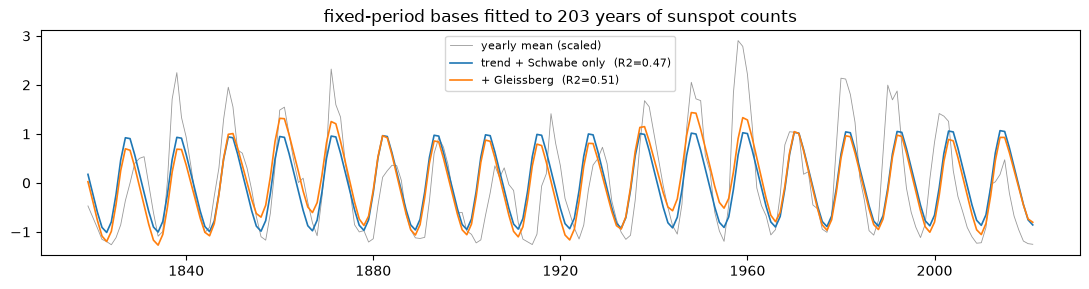

In [14]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(sunspot_years, sun, lw=0.6, color="0.6", label="yearly mean (scaled)")
ax.plot(sunspot_years, recon_one.detach(), lw=1.2, label=f"trend + Schwabe only  (R2={r2_one:.2f})")
ax.plot(sunspot_years, recon_two.detach(), lw=1.2, label=f"+ Gleissberg  (R2={r2_two:.2f})")
ax.legend(fontsize=8)
ax.set_title("fixed-period bases fitted to 203 years of sunspot counts")
plt.tight_layout()


Adding the Gleissberg term is a real, if modest, improvement — and the capacity-matched
control (more harmonics of the *same* 11-year period, same parameter count) gets none
of it: R² sits exactly where the plain Schwabe fit left it. The gain is specifically
from naming the second period, not from having more numbers to fit with — the same
control `05_gates_highways_moe.ipynb` 5.6 runs on a completely different mechanism.

What is left over (R² a little above 0.5, both fits) is the part 203 years cannot buy:
2.3 repeats of Gleissberg is enough to see that the cycle heights rise and fall on
roughly that schedule, not enough to pin its period the way 18.5 Schwabe repeats pin
11 years. And the Suess/de Vries cycle at ~210 years is not even a full repeat in this
record — there is no basis you could add, at any harmonic count, that this dataset
could tell you was right. That is the concrete version of DAV's unfinished suggestion:
not "the decomposition fails," but "here is exactly how much of it 203 years can
support, and here is the line past which you would need more data, not a better model."


## 3.8 How this differs from the reference implementation

Read
[`neuralforecast/models/nbeats.py`](https://github.com/Nixtla/neuralforecast/blob/main/neuralforecast/models/nbeats.py)
next to what you just wrote. `TrendBasis`, `SeasonalityBasis`, `IdentityBasis` and `NBEATSBlock`
are all plain `nn.Module`s taking plain tensors there too, and their stacking loop is the same
five lines. Two deliberate differences:

- **They reverse the window** (`insample_y.flip(dims=(-1,))`) so the most recent step comes first,
  and orient the bases to match. We keep forward time order. Self-consistent either way.
- **Their Fourier frequencies are derived from `forecast_size`**; ours are harmonics of a period
  *you name*. Ours is more readable and connects directly to `ts_features.py`'s bands, but it
  requires you to know the period — which `02_basemodels` section 2.1 is how you find out.

Their top-level `NBEATS` class subclasses a Lightning `BaseModel` and takes a `windows_batch`
dict, which is the only part that does not transfer. That is the general shape of these libraries:
the ideas are portable, the plumbing is not.

## What to take from this

- **A basis is a constraint on what the model may say**, and constraints are how you get
  interpretability. The stacks separate because the architecture forced them to, not because we
  plotted them apart.
- **Designed features and designed *outputs* are not the same move.** `09_composition_extra` fed a
  trend slope in and the model ignored it, because a linear layer can already compute one.
  Here the trend is what the model is allowed to predict in, and it cannot be ignored.
- **Read the spectrum before you pick a period.** The seasonality stack is only as useful as the
  period you gave it, and section 3.6 shows what a wrong one buys you.
- **Count your windows before you reach for structure.** An inductive bias is a substitute for
  data. With 72k windows the linear layer learns the structure directly and wins; with 1.4k it
  overfits and the constrained model wins. Same architectures, same code, opposite verdicts.
- **Interpretability and accuracy are different axes.** The model you can interrogate was not the
  model that scored best, on either series. That is normal, and which one you ship is a question
  about who has to defend the forecast.
- **You still have to beat the cheap baseline.** Whatever the table said, it said it about this
  series at this horizon with this much data.

## Exercises

**E1 — was it really a fair fight?** Section 3.4 quotes eight configurations run outside the
notebook. Reproduce two or three of them (start with `generic(hidden=512)` at 40 epochs) and
confirm the gap does not close. Then design one more that you think *should* close it, and say
in advance why. This is the ablation habit from `09_composition_extra`, applied to somebody else's
claim — including mine.

**E2 — the period is a hyperparameter.** The seasonality stack is fixed to 24 hours. Add a third
stack at 168 hours (weekly) and re-measure. Does the weekly stack pick up anything, and does the
24-hour stack's contribution shrink when it does?

**E3 — how much basis is enough?** Sweep `harmonics` over 1, 3, 6, 12 and `degree` over 1, 2, 3.
Plot score against the number of basis functions. Where does adding shapes stop helping, and how
does that compare with the band structure `ts_features.spectral_bands` found?

**E4 — generic versus interpretable, on your own terms.** The generic model has an identity basis:
it can predict any shape. The interpretable one cannot. Measure both as you shrink the training
set (2000, 500, 200 windows). Which one degrades faster, and why would you expect that?

**E5 — search it with ray.** `06_search.ipynb` runs exactly this search (`degree`, `harmonics`, `hidden`, gate on/off) on `pedestrian_counts`. Before opening it, write down which of those axes you expect to matter, the same way `1_pytorch_intro/04_search` asked you to before its own search ran.

**E6 — the honest comparison.** Add PatchTST from `04_probabilistic` to the table on this series,
with the same seeds and the same budget. It has no notion of trend or seasonality and learns
everything from data. On a series this seasonal, does the inductive bias pay?